# 02 - Demand forecasting

Runs on **Google Colab or locally**. Backtests five models (seasonal naive, moving average, SARIMA with
Fourier terms, Prophet, global LightGBM) on weekly units per category, picks a champion and writes the
12-week forecast. All logic is in `src/sca/forecasting.py` and `src/sca/forecast_report.py`; this notebook
only runs it and shows the results.

- **Local:** run `python -m sca ingest` once, then run all cells (about a minute).
- **Colab:** create `sca_processed.zip` locally with
  `Compress-Archive -Path data\processed\*.parquet, data\processed\meta.json -DestinationPath sca_processed.zip`,
  run all cells, upload the zip when asked, and unzip the downloaded `forecast_outputs.zip` into the repo root.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    REPO = "https://github.com/swarnkarkuldeep/SupplyPulse.git"  # change if you fork it
    if not Path("SupplyPulse").exists():
        subprocess.run(["git", "clone", "-q", REPO], check=True)
    os.chdir("SupplyPulse")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", ".", "--no-deps"], check=True)
else:
    # Local run: the notebook lives in notebooks/, so work from the repo root.
    root = Path.cwd()
    root = root.parent if root.name == "notebooks" else root
    os.chdir(root)
print("Running on", "Colab" if IN_COLAB else "this machine", "from", Path.cwd())

Running on this machine from F:\SupplyPulse


## Data

In [2]:
import zipfile

if IN_COLAB:
    from google.colab import files

    up = files.upload()  # choose sca_processed.zip
    Path("data/processed").mkdir(parents=True, exist_ok=True)
    zipfile.ZipFile(next(iter(up))).extractall("data/processed")
needed = Path("data/processed/fact_order_items.parquet")
assert needed.exists(), "run `python -m sca ingest` first (or upload sca_processed.zip on Colab)"
print("processed data found:", sorted(p.name for p in Path("data/processed").glob("*.parquet")))

processed data found: ['dim_category.parquet', 'dim_customer.parquet', 'dim_date.parquet', 'dim_geography.parquet', 'dim_product.parquet', 'dim_shipping_mode.parquet', 'fact_order_items.parquet']


## Run the forecast

In [3]:
import yaml

cfg = yaml.safe_load(open("config.yaml"))
cfg["forecast"]["n_jobs"] = 2  # parallel series fits for SARIMA / Prophet
yaml.safe_dump(cfg, open("run_config.yaml", "w"))
proc = subprocess.run(
    [sys.executable, "-m", "sca", "forecast", "--config", "run_config.yaml"], capture_output=True, text=True
)
print(proc.stdout[-1500:])
assert proc.returncode == 0, proc.stderr[-3000:]
Path("run_config.yaml").unlink()

series: 9 categories + TOTAL, 143 weeks (2015-01-05 to 2017-09-25)
seasonal_naive: fold 1/5 done
seasonal_naive: fold 2/5 done
seasonal_naive: fold 3/5 done
seasonal_naive: fold 4/5 done
seasonal_naive: fold 5/5 done
moving_average: fold 1/5 done
moving_average: fold 2/5 done
moving_average: fold 3/5 done
moving_average: fold 4/5 done
moving_average: fold 5/5 done
sarima: fold 1/5 done
sarima: fold 2/5 done
sarima: fold 3/5 done
sarima: fold 4/5 done
sarima: fold 5/5 done
prophet: fold 1/5 done
prophet: fold 2/5 done
prophet: fold 3/5 done
prophet: fold 4/5 done
prophet: fold 5/5 done
lightgbm: fold 1/5 done
lightgbm: fold 2/5 done
lightgbm: fold 3/5 done
lightgbm: fold 4/5 done
lightgbm: fold 5/5 done
forecast: champion sarima, 9 categories, WAPE 8.1%



## Results

,model,wape,mape,mae,bias,bias_pct,n,wape_improvement_vs_baseline
0,seasonal_naive,0.1061,0.1127,26.0833,-0.0111,-0.0000,360.0,0.0000
1,moving_average,0.0829,0.0859,20.3653,1.1306,0.0046,360.0,0.2192
2,sarima,0.0813,0.0851,19.9711,2.1191,0.0086,360.0,0.2343
3,prophet,0.0885,0.0934,21.7433,1.5237,0.0062,360.0,0.1664
4,lightgbm,0.0873,0.0900,21.4563,0.7867,0.0032,360.0,0.1774


## Champion

**SARIMA (Fourier).** SARIMA (Fourier) has the lowest pooled backtest WAPE (8.1%), 23.4% better than seasonal naive (10.6%). It beats the simple moving average by only 0.2 percentage points, which is within backtest noise: a flat 8-week average is almost as good here. The champion is chosen once, for all categories, from pooled backtest WAPE. Choosing per category would pick the best of 5 models on only 40 test weeks each, which overstates accuracy.



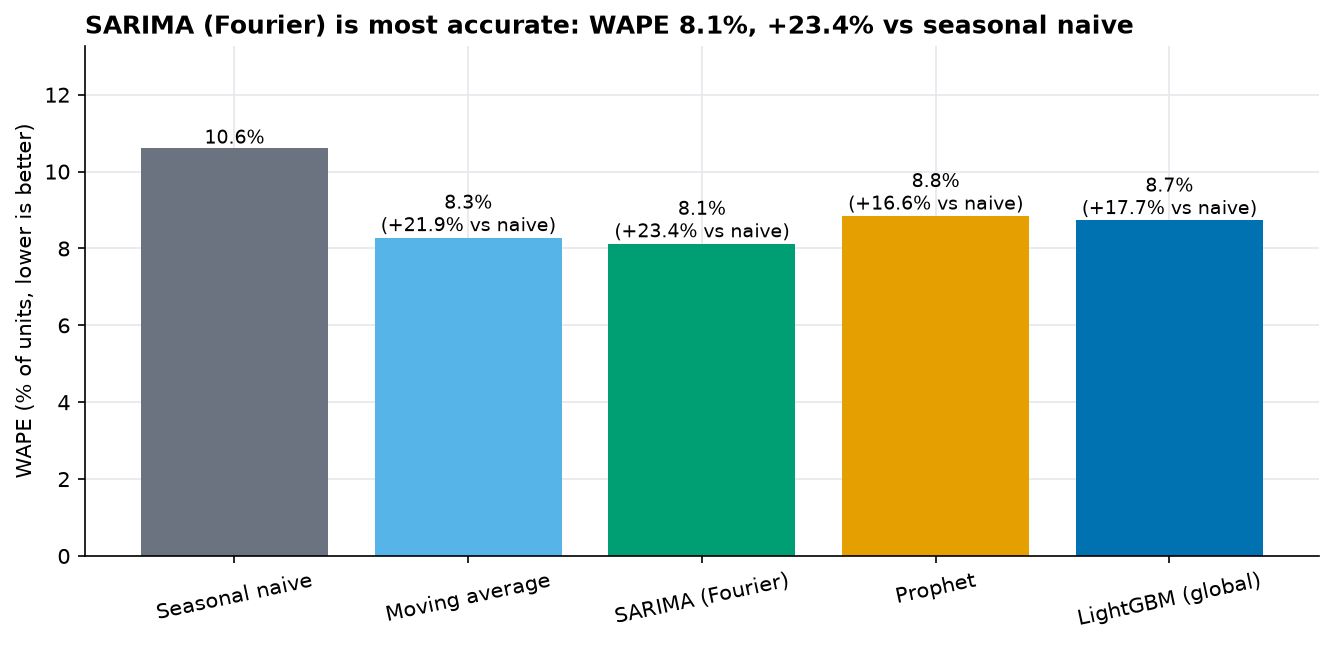

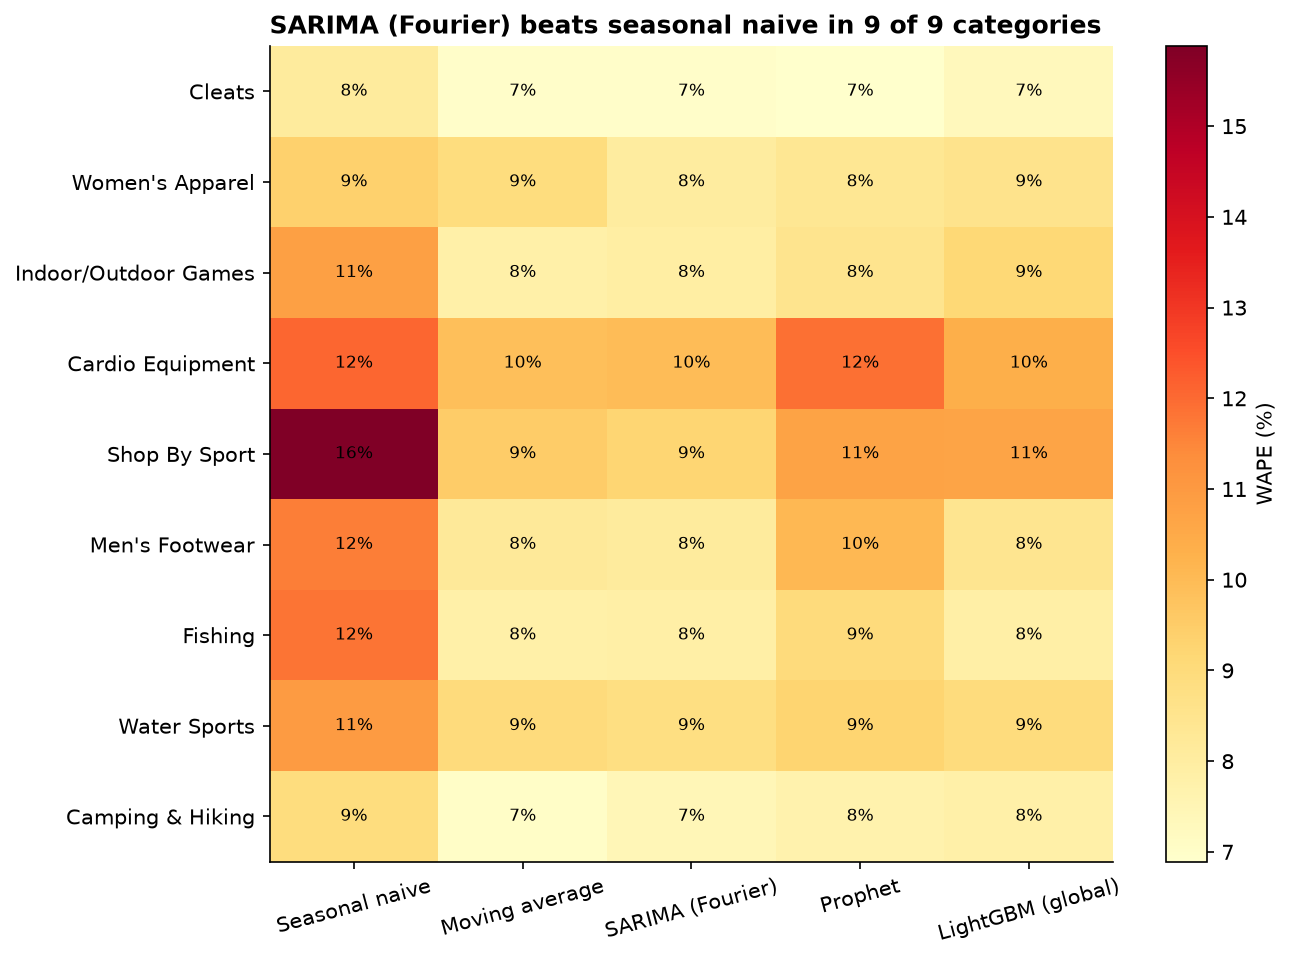

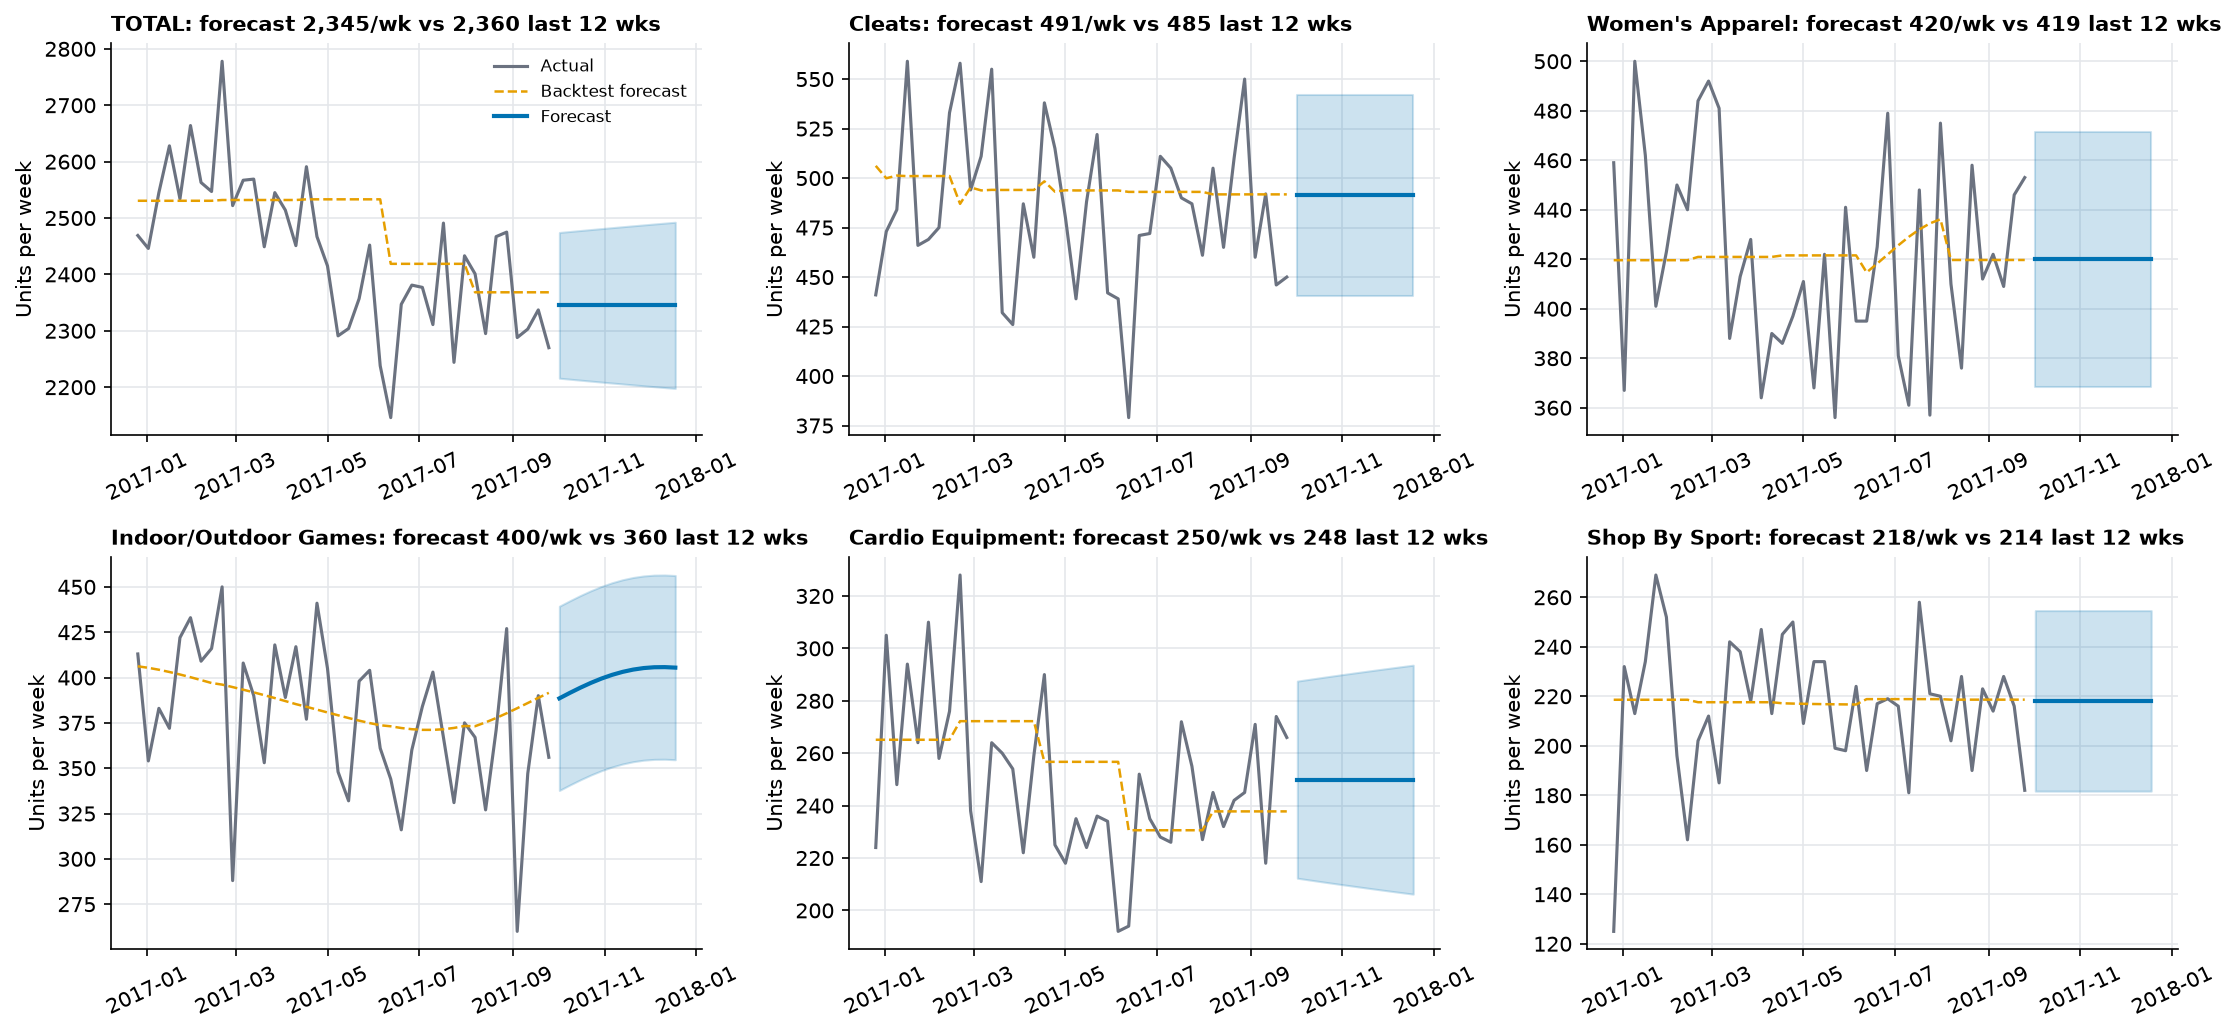

In [4]:
import pandas as pd
from IPython.display import Image, Markdown, display

out = Path("data/processed/forecast")
display(pd.read_csv(out / "metrics_overall.csv").round(4))
report = Path("reports/forecast_results.md").read_text(encoding="utf-8")
display(Markdown("## Champion" + report.split("## Champion")[1].split("## 12-week")[0]))
for fig in ("forecast_01_model_wape", "forecast_02_category_wape", "forecast_03_forecasts"):
    display(Image(f"reports/figures/{fig}.png"))

## Outputs

In [5]:
if IN_COLAB:
    subprocess.run(
        "zip -qr forecast_outputs.zip reports/forecast_results.md reports/figures/forecast_*.png "
        "data/processed/forecast",
        shell=True,
        check=True,
    )
    from google.colab import files

    files.download("forecast_outputs.zip")
else:
    print("Local run: outputs are already in reports/ and data/processed/forecast/.")

Local run: outputs are already in reports/ and data/processed/forecast/.
